# Traffic Sign Recognition using CNN
**AI/ML Specialisation Capstone – Project 6 (Autonomous Mobility / Computer Vision)**
Dataset: German Traffic Sign Recognition Benchmark (GTSRB)  
**Author:** Aman Sah (individual project)

## 1. Problem Statement & Scope
**Task:** Classify a cropped traffic-sign image into one of 43 sign categories (multi-class image classification).

**Objective:** Build a robust classifier (custom CNN baseline + transfer-learning model) and deploy a prototype where a user uploads a sign image and receives the predicted class.

**Target users:** CV learners, smart-mobility teams, ADAS prototyping teams, road-safety analysts.

| In scope | Out of scope |
|---|---|
| GTSRB images and labels; baseline CNN + transfer learning; class imbalance and augmentation; per-class evaluation; upload-based prediction UI | Real-time video; detecting signs in full street scenes; production-grade autonomous driving |

**Measurable ML task & success criteria**
- Primary metrics: accuracy, **macro F1**, per-class recall, confusion matrix, top-5 accuracy, inference latency.
- The advanced model should clearly beat the baseline on the held-out official test set.
- Report failure cases and robustness to blur / low light honestly.

> ⚠️ Learning prototype only – **not** a safety-certified autonomous-driving component.

## 2. Notebook Roadmap
1. Setup → 2. Data access → 3. Load & validate → 4. EDA → 5. Preprocessing & splits → 6. Baseline CNN → 7. Transfer learning (MobileNetV2) → 8. Hyperparameter experiments → 9. Final evaluation → 10. Error analysis & robustness → 11. Export model + Streamlit app + README → 12. Demo predictions → 13. Conclusions

## 3. Setup

In [1]:
import os, sys, time, json, zipfile, urllib.request, random, warnings
from pathlib import Path
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, recall_score, top_k_accuracy_score)
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- Configuration ----
IMG_SIZE   = 64          # all images resized to 64x64 (problem statement: 32 or 64)
NUM_CLASSES = 43
BATCH_SIZE = 128
DATA_DIR   = Path("data")           # raw data + extracted archives
ARTIFACTS  = Path("artifacts")      # trained models, reports, figures
for d in (DATA_DIR, ARTIFACTS): d.mkdir(exist_ok=True)

print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow 2.19.1 | GPUs: []


In [2]:
CLASS_NAMES = [
 "Speed limit (20km/h)","Speed limit (30km/h)","Speed limit (50km/h)","Speed limit (60km/h)",
 "Speed limit (70km/h)","Speed limit (80km/h)","End of speed limit (80km/h)","Speed limit (100km/h)",
 "Speed limit (120km/h)","No passing","No passing for vehicles over 3.5t","Right-of-way at next intersection",
 "Priority road","Yield","Stop","No vehicles","Vehicles over 3.5t prohibited","No entry",
 "General caution","Dangerous curve to the left","Dangerous curve to the right","Double curve",
 "Bumpy road","Slippery road","Road narrows on the right","Road work","Traffic signals",
 "Pedestrians","Children crossing","Bicycles crossing","Beware of ice/snow","Wild animals crossing",
 "End of all speed and passing limits","Turn right ahead","Turn left ahead","Ahead only",
 "Go straight or right","Go straight or left","Keep right","Keep left","Roundabout mandatory",
 "End of no passing","End of no passing by vehicles over 3.5t"]
assert len(CLASS_NAMES) == NUM_CLASSES

## 4. Data Access
Source: official GTSRB benchmark (<https://benchmark.ini.rub.de/gtsrb_dataset.html>), whose archives are hosted at `sid.erda.dk`.
The cell downloads the archives once and extracts them into `data/` (re-runs skip existing files).

*If the official host is unreachable, download the Kaggle mirror manually and place `GTSRB/Final_Training/Images`, `GTSRB/Final_Test/Images` and `GT-final_test.csv` under `data/`.*

In [3]:
BASE = "https://sid.erda.dk/public/archives/daaeac0d7ce1152aea9b61d9f1e19370/"
ARCHIVES = {
    "GTSRB_Final_Training_Images.zip": BASE + "GTSRB_Final_Training_Images.zip",
    "GTSRB_Final_Test_Images.zip":     BASE + "GTSRB_Final_Test_Images.zip",
    "GTSRB_Final_Test_GT.zip":         BASE + "GTSRB_Final_Test_GT.zip",
}
def fetch(name, url):
    zpath = DATA_DIR / name
    if not zpath.exists():
        print("Downloading", name, "...")
        urllib.request.urlretrieve(url, zpath)
    marker = DATA_DIR / (name + ".extracted")
    if not marker.exists():
        print("Extracting", name, "...")
        with zipfile.ZipFile(zpath) as z: z.extractall(DATA_DIR)
        marker.touch()

if not (DATA_DIR / "GTSRB" / "Final_Training" / "Images").exists():
    for n, u in ARCHIVES.items(): fetch(n, u)

TRAIN_ROOT = DATA_DIR / "GTSRB" / "Final_Training" / "Images"
TEST_ROOT  = DATA_DIR / "GTSRB" / "Final_Test" / "Images"
TEST_CSV   = next(DATA_DIR.rglob("GT-final_test.csv"))
print(TRAIN_ROOT.exists(), TEST_ROOT.exists(), TEST_CSV)

True True data/GT-final_test.csv


## 5. Load Data, Validate Labels & File Structure
Each training class folder has a `GT-xxxxx.csv` (`;`-separated) with the sign's **ROI** (region of interest). We crop to the ROI to remove background border, then resize to 64×64.

**Important – leakage control:** GTSRB training images come in *tracks* of 30 frames of the same physical sign (`<track>_<frame>.ppm`). A random split would put near-duplicate frames in train and validation, inflating scores. We therefore keep a `track` id and split **by track**. The official test set is held out entirely.

In [4]:
def load_train_index():
    rows = []
    for cdir in sorted(TRAIN_ROOT.iterdir()):
        if not cdir.is_dir(): continue
        df = pd.read_csv(cdir / f"GT-{cdir.name}.csv", sep=";")
        df["path"] = df["Filename"].apply(lambda f: str(cdir / f))
        df["track"] = cdir.name + "_" + df["Filename"].str.split("_").str[0]
        rows.append(df)
    return pd.concat(rows, ignore_index=True)

train_df = load_train_index()
test_df  = pd.read_csv(TEST_CSV, sep=";")
test_df["path"] = test_df["Filename"].apply(lambda f: str(TEST_ROOT / f))

# ---- validation checks ----
assert train_df["ClassId"].between(0, NUM_CLASSES-1).all() and test_df["ClassId"].between(0, NUM_CLASSES-1).all()
assert train_df["ClassId"].nunique() == NUM_CLASSES
missing = [p for p in list(train_df.path) + list(test_df.path) if not os.path.exists(p)]
print(f"Train images: {len(train_df):,} | Test images: {len(test_df):,} | Classes: {train_df.ClassId.nunique()}")
print(f"Tracks in train: {train_df.track.nunique():,} | Missing files: {len(missing)}")
train_df.head()

Train images: 39,209 | Test images: 12,630 | Classes: 43
Tracks in train: 1,307 | Missing files: 0


,Filename,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,path,track
0,00000_00000.ppm,29,30,5,6,24,25,0,data/GTSRB/Final_Training/Images/00000/00000_0...,00000_00000
1,00000_00001.ppm,30,30,5,5,25,25,0,data/GTSRB/Final_Training/Images/00000/00000_0...,00000_00000
2,00000_00002.ppm,30,30,5,5,25,25,0,data/GTSRB/Final_Training/Images/00000/00000_0...,00000_00000
3,00000_00003.ppm,31,31,5,5,26,26,0,data/GTSRB/Final_Training/Images/00000/00000_0...,00000_00000
4,00000_00004.ppm,30,32,5,6,25,26,0,data/GTSRB/Final_Training/Images/00000/00000_0...,00000_00000


In [5]:
# Crop each image to its sign ROI (Roi.X2/Y2 are inclusive) and resize to IMG_SIZE x IMG_SIZE
def load_images(df, size=IMG_SIZE):
    X = np.empty((len(df), size, size, 3), dtype=np.uint8)
    x1, y1, x2, y2 = (df[c].values for c in ["Roi.X1", "Roi.Y1", "Roi.X2", "Roi.Y2"])
    for i, p in enumerate(df["path"].values):
        img = Image.open(p).convert("RGB").crop((x1[i], y1[i], x2[i] + 1, y2[i] + 1))
        X[i] = np.asarray(img.resize((size, size), Image.BILINEAR))
    return X

t0 = time.time()
X_all  = load_images(train_df); y_all = train_df["ClassId"].values
X_test = load_images(test_df);  y_test = test_df["ClassId"].values
print(f"Loaded in {time.time()-t0:.0f}s | X_all {X_all.shape} | X_test {X_test.shape}")

Loaded in 5s | X_all (39209, 64, 64, 3) | X_test (12630, 64, 64, 3)


## 6. Exploratory Data Analysis

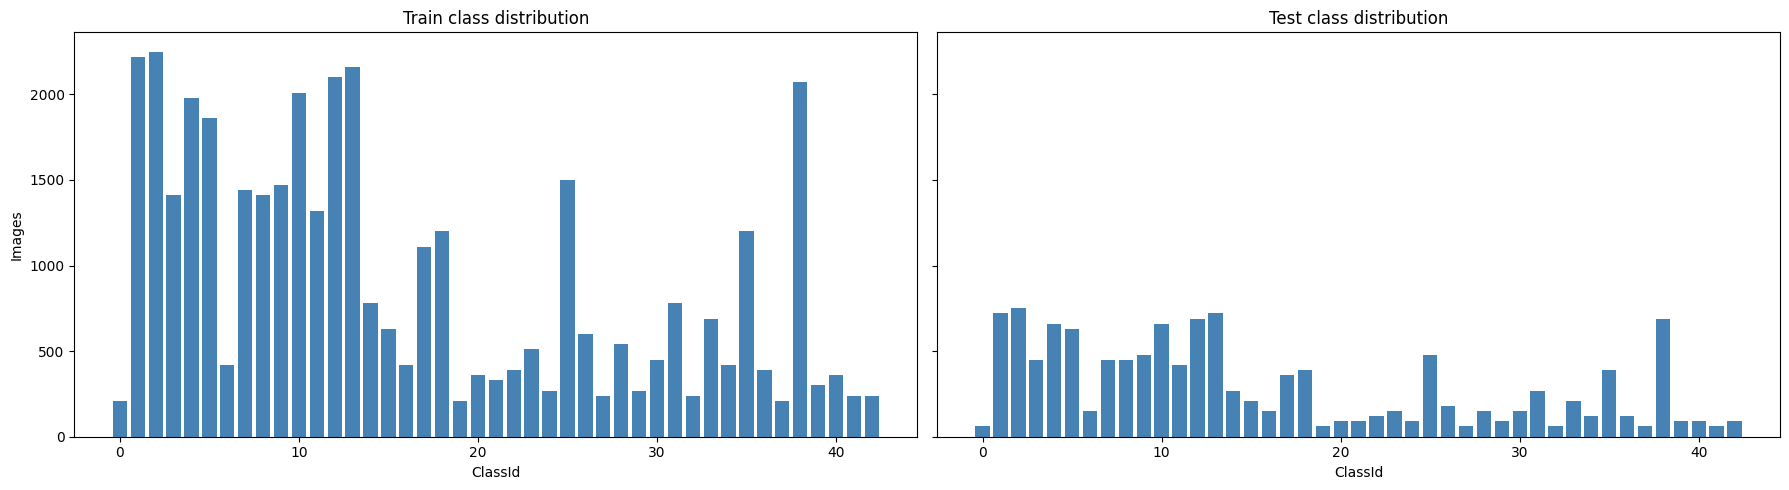

Largest class: Speed limit (50km/h) (2250) | Smallest: Go straight or left (210) | Imbalance ratio: 10.7x


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(18, 5), sharey=True)
for a, (name, y) in zip(ax, [("Train", y_all), ("Test", y_test)]):
    cnt = pd.Series(y).value_counts().sort_index()
    a.bar(cnt.index, cnt.values, color="steelblue"); a.set_title(f"{name} class distribution"); a.set_xlabel("ClassId")
ax[0].set_ylabel("Images"); plt.tight_layout(); plt.show()

cnt = pd.Series(y_all).value_counts()
print(f"Largest class: {CLASS_NAMES[cnt.idxmax()]} ({cnt.max()}) | Smallest: {CLASS_NAMES[cnt.idxmin()]} ({cnt.min()}) | Imbalance ratio: {cnt.max()/cnt.min():.1f}x")

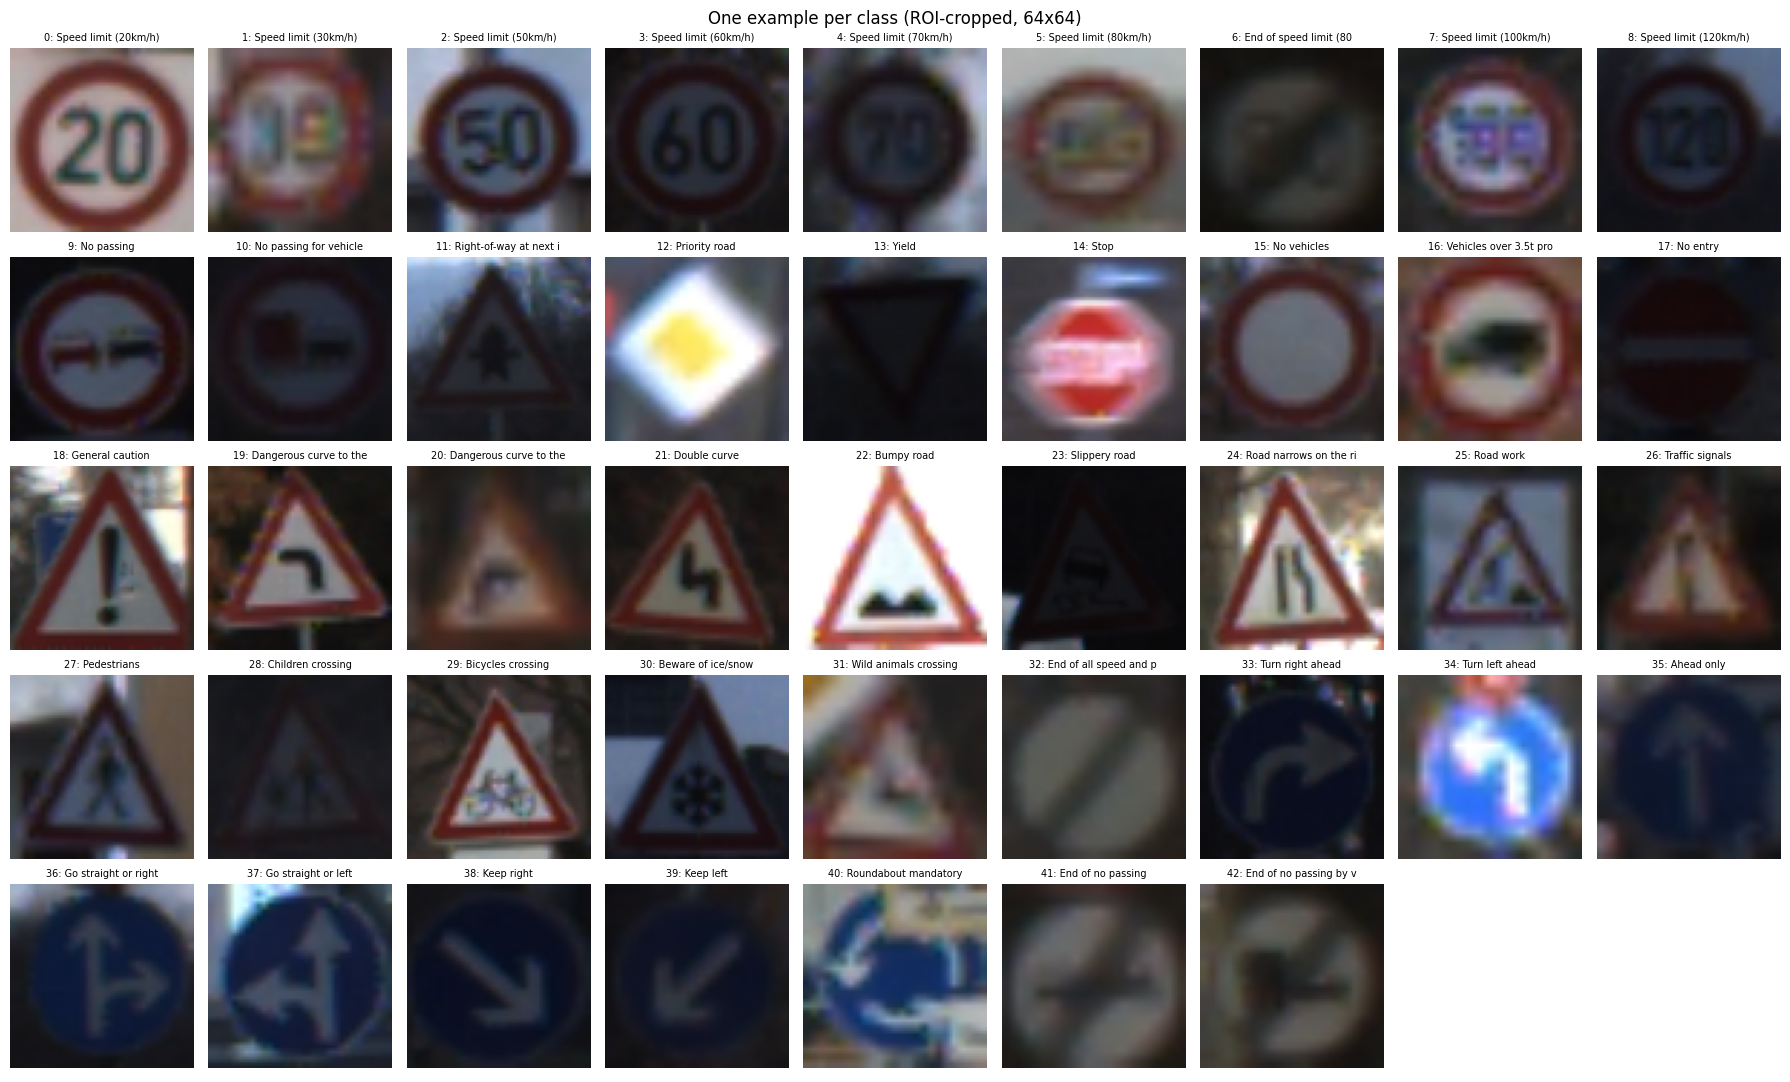

In [7]:
# One sample per class
fig, axes = plt.subplots(5, 9, figsize=(18, 11))
for k, a in enumerate(axes.ravel()):
    a.axis("off")
    if k < NUM_CLASSES:
        idx = np.where(y_all == k)[0][len(np.where(y_all == k)[0]) // 2]
        a.imshow(X_all[idx]); a.set_title(f"{k}: {CLASS_NAMES[k][:22]}", fontsize=7)
plt.suptitle("One example per class (ROI-cropped, 64x64)"); plt.tight_layout(); plt.show()

      Width  Height
min    25.0    25.0
mean   50.8    50.3
max   243.0   225.0


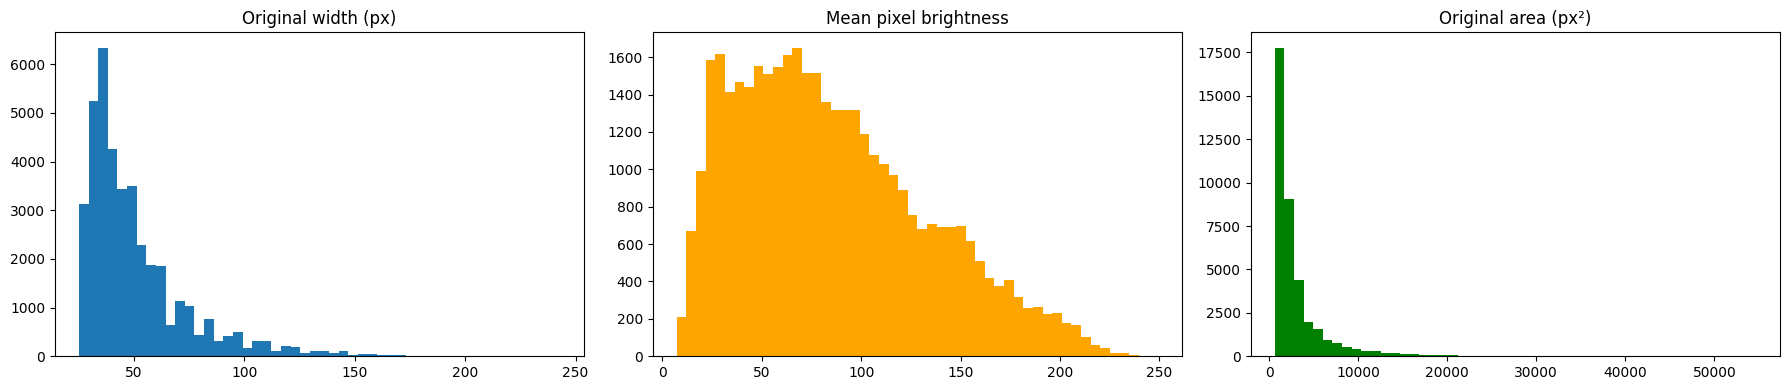

Images with original width < 30px: 3121 | mean brightness < 50 (very dark): 10657


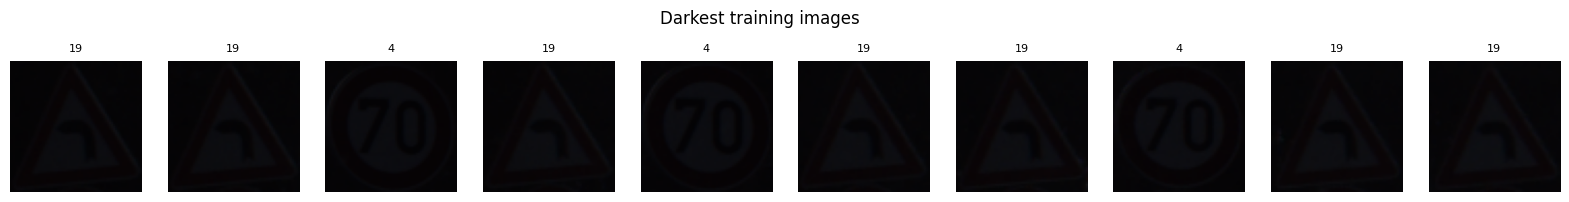

In [8]:
# Data quality: original image sizes & brightness (small/blurry/dark signs are a known risk)
print(train_df[["Width", "Height"]].describe().loc[["min", "mean", "max"]].round(1))
brightness = X_all.reshape(len(X_all), -1).mean(1)
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].hist(train_df.Width, bins=50); ax[0].set_title("Original width (px)")
ax[1].hist(brightness, bins=50, color="orange"); ax[1].set_title("Mean pixel brightness")
ax[2].hist(train_df.Width * train_df.Height, bins=50, color="green"); ax[2].set_title("Original area (px²)")
plt.tight_layout(); plt.show()
print("Images with original width < 30px:", (train_df.Width < 30).sum(), "| mean brightness < 50 (very dark):", (brightness < 50).sum())

# Darkest examples
dark = np.argsort(brightness)[:10]
fig, axes = plt.subplots(1, 10, figsize=(20, 2.4))
for a, i in zip(axes, dark): a.imshow(X_all[i]); a.axis("off"); a.set_title(str(y_all[i]), fontsize=8)
plt.suptitle("Darkest training images"); plt.show()

**EDA observations:**
- **Class imbalance:** the largest class (Speed limit 50 km/h) has 2,250 training images and the smallest have 210 – a **10.7× ratio**, with the same skew in the test set → balanced class weights + augmentation, and macro-F1 / per-class recall rather than accuracy alone.
- **Small images:** originals are 25–243 px wide (mean ≈ 51 px); **3,121 images (8%) are narrower than 30 px**, so many signs are small and blurry once resized to 64×64.
- **Lighting:** **10,657 images (27%) have mean brightness below 50/255** → brightness/contrast augmentation.
- **Tracks:** the 39,209 training images come from 1,307 physical signs (~30 frames each); frames within a track are near-duplicates → split by track to avoid leakage.
- **No horizontal flips:** several classes are mirror pairs (Turn left/right ahead, Keep left/right, Dangerous curve left/right), so flipping would change the label.

## 7. Preprocessing & Train / Validation / Test Splits
- **Train / validation:** ~80/20 split that is **stratified by class and grouped by track** (`StratifiedGroupKFold`, one of 5 folds), so no track is split across sets *and* every class – including the rarest – appears in validation.
- **Test:** the official GTSRB test set (12,630 images) – never touched until final evaluation.
- **Normalisation:** pixels are scaled inside the model (`Rescaling`) so the saved artifact accepts raw 0–255 images – this guarantees identical preprocessing in training and the deployed app.

In [9]:
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
# stratification is approximate with groups, so take the first fold whose validation part contains every class
tr_idx, va_idx = next((tr, va) for tr, va in sgkf.split(X_all, y_all, groups=train_df["track"].values)
                      if len(np.unique(y_all[va])) == NUM_CLASSES)
X_train, y_train = X_all[tr_idx], y_all[tr_idx]
X_val,   y_val   = X_all[va_idx], y_all[va_idx]

assert set(train_df.track.values[tr_idx]).isdisjoint(train_df.track.values[va_idx])  # no leakage
print(f"train {X_train.shape[0]:,} | val {X_val.shape[0]:,} | test {X_test.shape[0]:,}")
assert set(y_val) == set(range(NUM_CLASSES)), "every class must appear in validation"
print("Smallest per-class val count:", np.bincount(y_val, minlength=NUM_CLASSES).min())

# Class weights for imbalance
cw = compute_class_weight("balanced", classes=np.arange(NUM_CLASSES), y=y_train)
CLASS_WEIGHT = {i: float(w) for i, w in enumerate(cw)}
print("Class weight range: %.2f – %.2f" % (cw.min(), cw.max()))

train 31,349 | val 7,860 | test 12,630
Smallest per-class val count: 30
Class weight range: 0.41 – 4.86


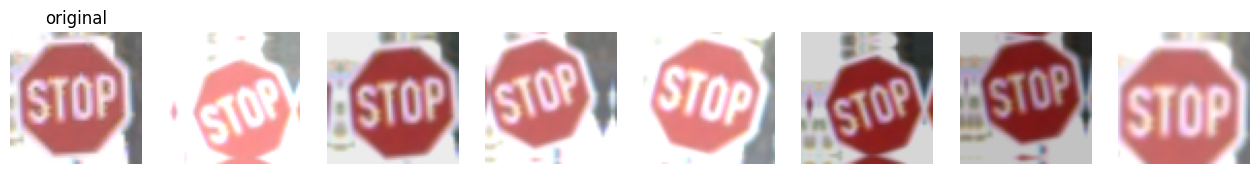

In [10]:
# Augmentation pipeline (no flips!). Applied only during training.
def make_augmenter():
    return keras.Sequential([
        layers.RandomRotation(0.08),                          # ±~14°
        layers.RandomTranslation(0.1, 0.1),
        layers.RandomZoom(0.15),
        layers.RandomContrast(0.3),
        layers.RandomBrightness(0.3, value_range=(0, 255)),
    ], name="augment")

def make_ds(X, y, training):
    ds = tf.data.Dataset.from_tensor_slices((X, y))
    if training: ds = ds.shuffle(len(X), seed=SEED)
    ds = ds.batch(BATCH_SIZE).map(lambda x, y: (tf.cast(x, tf.float32), y), num_parallel_calls=tf.data.AUTOTUNE)
    return ds.prefetch(tf.data.AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(X_train, y_train, True), make_ds(X_val, y_val, False), make_ds(X_test, y_test, False)

# visualise augmentation
aug = make_augmenter()
sample = X_train[np.where(y_train == 14)[0][0]][None].astype("float32")   # a Stop sign
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
axes[0].imshow(sample[0].astype("uint8")); axes[0].set_title("original")
for a in axes[1:]: a.imshow(np.clip(aug(sample, training=True)[0].numpy(), 0, 255).astype("uint8")); a.axis("off")
axes[0].axis("off"); plt.show()

## 8. Experiment Tracking Utilities
Every run logs its configuration, best validation metrics, parameter count and training time to `artifacts/experiments.csv`; training curves are plotted per run.

In [11]:
EXPERIMENTS = []
def evaluate_split(model, X, y):
    p = model.predict(X.astype("float32"), batch_size=256, verbose=0)
    pred = p.argmax(1)
    return dict(acc=accuracy_score(y, pred), macro_f1=f1_score(y, pred, average="macro"),
                top5=top_k_accuracy_score(y, p, k=5, labels=np.arange(NUM_CLASSES))), p

def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    for k in ("loss", "val_loss"): ax[0].plot(h[k], label=k)
    for k in ("accuracy", "val_accuracy"): ax[1].plot(h[k], label=k)
    ax[0].set_title(title + " – loss"); ax[1].set_title(title + " – accuracy")
    for a in ax: a.legend(); a.set_xlabel("epoch")
    plt.tight_layout(); plt.show()

def log_run(name, model, history, cfg, secs):
    m, _ = evaluate_split(model, X_val, y_val)
    rec = dict(run=name, **cfg, params=model.count_params(), train_secs=round(secs),
               val_acc=round(m["acc"], 4), val_macro_f1=round(m["macro_f1"], 4), val_top5=round(m["top5"], 4))
    EXPERIMENTS.append(rec)
    pd.DataFrame(EXPERIMENTS).to_csv(ARTIFACTS / "experiments.csv", index=False)
    return rec

def fit(model, name, cfg, epochs, lr, use_aug=True, class_weight=True, verbose=2):
    aug_layer = make_augmenter() if use_aug else None
    ds = train_ds.map(lambda x, y: (aug_layer(x, training=True), y),
                      num_parallel_calls=tf.data.AUTOTUNE) if use_aug else train_ds
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    cbs = [keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True, monitor="val_loss"),
           keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=2, min_lr=1e-6),
           keras.callbacks.CSVLogger(str(ARTIFACTS / f"trainlog_{name}.csv"))]          # per-epoch curves for tracking
    t0 = time.time()
    h = model.fit(ds, validation_data=val_ds, epochs=epochs, callbacks=cbs,
                  class_weight=CLASS_WEIGHT if class_weight else None, verbose=verbose)
    return h.history, time.time() - t0

## 9. Baseline Model – Custom CNN
Three conv blocks (Conv-BN-Conv-BN-MaxPool-Dropout) with 32/64/128 filters → global pooling → dense head. Raw 0–255 input is rescaled inside the model.

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 332,875 (1.27 MB)

 Trainable params: 331,979 (1.27 MB)

 Non-trainable params: 896 (3.50 KB)

...

245/245 - 62s - 252ms/step - accuracy: 0.9564 - loss: 0.1255 - val_accuracy: 0.9901 - val_loss: 0.0475 - learning_rate: 1.2500e-04


Epoch 24/25


245/245 - 62s - 252ms/step - accuracy: 0.9559 - loss: 0.1288 - val_accuracy: 0.9897 - val_loss: 0.0596 - learning_rate: 1.2500e-04


Epoch 25/25


245/245 - 62s - 254ms/step - accuracy: 0.9579 - loss: 0.1202 - val_accuracy: 0.9901 - val_loss: 0.0518 - learning_rate: 1.2500e-04


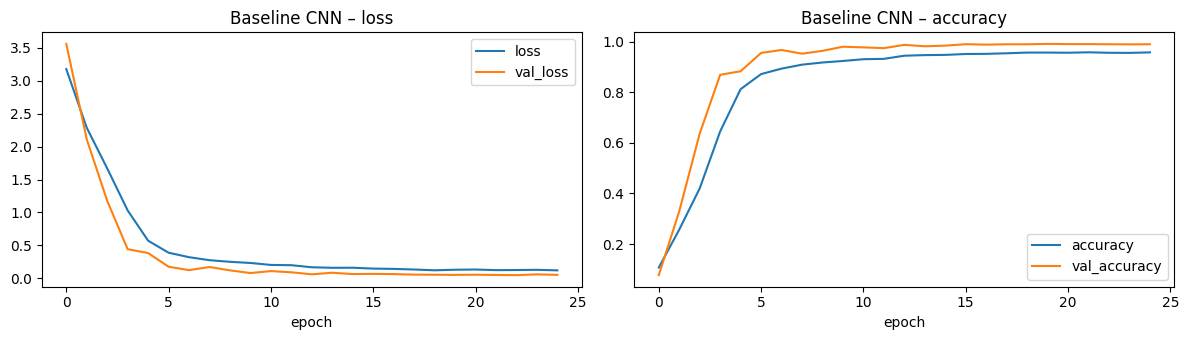

{'run': 'baseline_cnn', 'model': 'custom_cnn', 'lr': 0.001, 'dropout': 0.3, 'dense': 256, 'batch': 128, 'augment': True, 'class_weight': True, 'params': 332875, 'train_secs': 1696, 'val_acc': 0.9901, 'val_macro_f1': 0.9855, 'val_top5': np.float64(0.9962)}


In [12]:
def build_baseline(dropout=0.3, dense=256):
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Rescaling(1/255.)(inp)
    for f in (32, 64, 128):
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization()(x)
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization()(x)
        x = layers.MaxPooling2D()(x); x = layers.Dropout(dropout)(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense, activation="relu")(x); x = layers.Dropout(0.5)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="baseline_cnn")

baseline = build_baseline()
baseline.summary()
cfg = dict(model="custom_cnn", lr=1e-3, dropout=0.3, dense=256, batch=BATCH_SIZE, augment=True, class_weight=True)
hist, secs = fit(baseline, "baseline", cfg, epochs=25, lr=1e-3)
plot_history(hist, "Baseline CNN"); print(log_run("baseline_cnn", baseline, hist, cfg, secs))

## 10. Advanced Model – Transfer Learning (MobileNetV2)
ImageNet-pretrained **MobileNetV2** (light enough for edge/ADAS prototyping). Images are upsampled to 96×96 *inside* the model (pretrained filters work better at larger resolution).

**Two-phase training**
1. *Feature extraction* – freeze the backbone, train the new classification head.
2. *Fine-tuning* – unfreeze the top of the backbone (BatchNorm layers kept frozen) with a much lower learning rate.

Epoch 1/10


245/245 - 18s - 75ms/step - accuracy: 0.3897 - loss: 2.1140 - val_accuracy: 0.5594 - val_loss: 1.3706 - learning_rate: 1.0000e-03


Epoch 2/10


245/245 - 17s - 68ms/step - accuracy: 0.5630 - loss: 1.3330 - val_accuracy: 0.6122 - val_loss: 1.1971 - learning_rate: 1.0000e-03


Epoch 3/10


...

245/245 - 23s - 93ms/step - accuracy: 0.9257 - loss: 0.1795 - val_accuracy: 0.9067 - val_loss: 0.3857 - learning_rate: 2.5000e-05


Epoch 18/20


245/245 - 23s - 92ms/step - accuracy: 0.9272 - loss: 0.1796 - val_accuracy: 0.9167 - val_loss: 0.3288 - learning_rate: 2.5000e-05


Epoch 19/20


245/245 - 23s - 93ms/step - accuracy: 0.9318 - loss: 0.1644 - val_accuracy: 0.9084 - val_loss: 0.3677 - learning_rate: 1.2500e-05


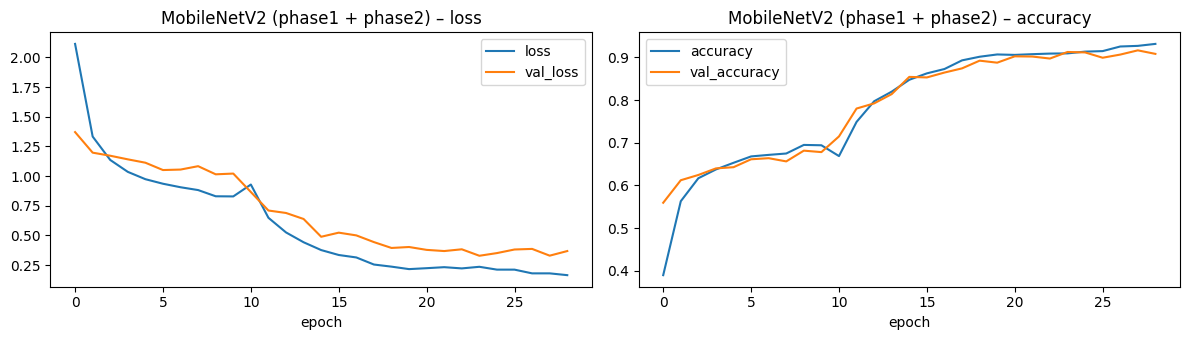

{'run': 'mobilenetv2_finetune', 'model': 'mobilenetv2', 'lr': '1e-3 -> 1e-4', 'dropout': 0.3, 'dense': 0, 'batch': 128, 'augment': True, 'class_weight': True, 'params': 2313067, 'train_secs': 599, 'val_acc': 0.9128, 'val_macro_f1': 0.8928, 'val_top5': np.float64(0.9882)}


In [13]:
def build_transfer(dropout=0.3, backbone_res=96):
    inp = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    x = layers.Resizing(backbone_res, backbone_res)(inp)
    x = layers.Rescaling(1/127.5, offset=-1)(x)                  # MobileNetV2 expects [-1, 1]
    base = keras.applications.MobileNetV2(input_shape=(backbone_res, backbone_res, 3), include_top=False,
                                          weights="imagenet", name="mobilenetv2")
    base.trainable = False
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x); x = layers.Dropout(dropout)(x)
    out = layers.Dense(NUM_CLASSES, activation="softmax")(x)
    return keras.Model(inp, out, name="mobilenetv2_transfer"), base

transfer, base = build_transfer()
cfg_t = dict(model="mobilenetv2", lr="1e-3 -> 1e-4", dropout=0.3, dense=0, batch=BATCH_SIZE, augment=True, class_weight=True)
h1, s1 = fit(transfer, "transfer_p1", cfg_t, epochs=10, lr=1e-3)           # phase 1: head only

base.trainable = True
for l in base.layers[:-40]: l.trainable = False                           # fine-tune top 40 layers
for l in base.layers:
    if isinstance(l, layers.BatchNormalization): l.trainable = False
h2, s2 = fit(transfer, "transfer_p2", cfg_t, epochs=20, lr=1e-4)           # phase 2: fine-tune
hist_t = {k: h1[k] + h2[k] for k in h1}
plot_history(hist_t, "MobileNetV2 (phase1 + phase2)")
print(log_run("mobilenetv2_finetune", transfer, hist_t, cfg_t, s1 + s2))

## 11. Hyperparameter Experiments
A small, time-boxed sweep on the baseline CNN (learning rate, dropout, optimizer-free regularisation via augmentation on/off, class weights on/off) to show the effect of key choices. Each run is capped at 8 epochs; results are logged to `experiments.csv`.

In [14]:
sweep = [
    dict(lr=1e-3, dropout=0.3, use_aug=True,  class_weight=True),    # reference
    dict(lr=3e-4, dropout=0.3, use_aug=True,  class_weight=True),
    dict(lr=3e-3, dropout=0.3, use_aug=True,  class_weight=True),
    dict(lr=1e-3, dropout=0.1, use_aug=True,  class_weight=True),
    dict(lr=1e-3, dropout=0.5, use_aug=True,  class_weight=True),
    dict(lr=1e-3, dropout=0.3, use_aug=False, class_weight=True),    # ablation: no augmentation
    dict(lr=1e-3, dropout=0.3, use_aug=True,  class_weight=False),   # ablation: no class weights
]
for i, s in enumerate(sweep):
    m = build_baseline(dropout=s["dropout"])
    cfg = dict(model="custom_cnn_sweep", lr=s["lr"], dropout=s["dropout"], dense=256, batch=BATCH_SIZE,
               augment=s["use_aug"], class_weight=s["class_weight"])
    h, secs = fit(m, f"sweep{i}", cfg, epochs=8, lr=s["lr"], use_aug=s["use_aug"], class_weight=s["class_weight"], verbose=0)
    print(log_run(f"sweep_{i}", m, h, cfg, secs))
    keras.backend.clear_session()

exp = pd.DataFrame(EXPERIMENTS)
exp.sort_values("val_macro_f1", ascending=False)

{'run': 'sweep_0', 'model': 'custom_cnn_sweep', 'lr': 0.001, 'dropout': 0.3, 'dense': 256, 'batch': 128, 'augment': True, 'class_weight': True, 'params': 332875, 'train_secs': 521, 'val_acc': 0.9613, 'val_macro_f1': 0.9503, 'val_top5': np.float64(0.9905)}


{'run': 'sweep_1', 'model': 'custom_cnn_sweep', 'lr': 0.0003, 'dropout': 0.3, 'dense': 256, 'batch': 128, 'augment': True, 'class_weight': True, 'params': 332875, 'train_secs': 796, 'val_acc': 0.9295, 'val_macro_f1': 0.929, 'val_top5': np.float64(0.9954)}


{'run': 'sweep_2', 'model': 'custom_cnn_sweep', 'lr': 0.003, 'dropout': 0.3, 'dense': 256, 'batch': 128, 'augment': True, 'class_weight': True, 'params': 332875, 'train_secs': 3675, 'val_acc': 0.9481, 'val_macro_f1': 0.9452, 'val_top5': np.float64(0.995)}


{'run': 'sweep_3', 'model': 'custom_cnn_sweep', 'lr': 0.001, 'dropout': 0.1, 'dense': 256, 'batch': 128, 'augment': True, 'class_weight': True, 'params': 332875, 'train_secs': 24964, 'val_acc': 0.9796, 'val_macro_f1': 0.9774, 'val_top5': np.float64(0.9967)}


{'run': 'sweep_4', 'model': 'custom_cnn_sweep', 'lr': 0.001, 'dropout': 0.5, 'dense': 256, 'batch': 128, 'augment': True, 'class_weight': True, 'params': 332875, 'train_secs': 784, 'val_acc': 0.9413, 'val_macro_f1': 0.9277, 'val_top5': np.float64(0.9917)}


{'run': 'sweep_5', 'model': 'custom_cnn_sweep', 'lr': 0.001, 'dropout': 0.3, 'dense': 256, 'batch': 128, 'augment': False, 'class_weight': True, 'params': 332875, 'train_secs': 724, 'val_acc': 0.9855, 'val_macro_f1': 0.9814, 'val_top5': np.float64(0.9957)}


{'run': 'sweep_6', 'model': 'custom_cnn_sweep', 'lr': 0.001, 'dropout': 0.3, 'dense': 256, 'batch': 128, 'augment': True, 'class_weight': False, 'params': 332875, 'train_secs': 778, 'val_acc': 0.9865, 'val_macro_f1': 0.981, 'val_top5': np.float64(0.9981)}


,run,model,lr,dropout,dense,batch,augment,class_weight,params,train_secs,val_acc,val_macro_f1,val_top5
0,baseline_cnn,custom_cnn,0.001,0.3,256,128,True,True,332875,1696,0.9901,0.9855,0.9962
7,sweep_5,custom_cnn_sweep,0.001,0.3,256,128,False,True,332875,724,0.9855,0.9814,0.9957
8,sweep_6,custom_cnn_sweep,0.001,0.3,256,128,True,False,332875,778,0.9865,0.9810,0.9981
5,sweep_3,custom_cnn_sweep,0.001,0.1,256,128,True,True,332875,24964,0.9796,0.9774,0.9967
2,sweep_0,custom_cnn_sweep,0.001,0.3,256,128,True,True,332875,521,0.9613,0.9503,0.9905
4,sweep_2,custom_cnn_sweep,0.003,0.3,256,128,True,True,332875,3675,0.9481,0.9452,0.9950
3,sweep_1,custom_cnn_sweep,0.0003,0.3,256,128,True,True,332875,796,0.9295,0.9290,0.9954
6,sweep_4,custom_cnn_sweep,0.001,0.5,256,128,True,True,332875,784,0.9413,0.9277,0.9917
1,mobilenetv2_finetune,mobilenetv2,1e-3 -> 1e-4,0.3,0,128,True,True,2313067,599,0.9128,0.8928,0.9882


**Reading the table (results):**
- The full-length baseline (25 epochs) is the best custom-CNN run: validation macro-F1 **0.986**. MobileNetV2 reached only 0.893 (discussed in §16).
- **Learning rate:** 1e-3 (reference, 0.950) beat 3e-4 (0.929) and 3e-3 (0.945) within the 8-epoch budget.
- **Dropout:** 0.1 (0.977) > 0.3 (0.950) > 0.5 (0.928) – heavier regularisation converges more slowly in a short budget.
- **Ablations:** no augmentation (0.981) and no class weights (0.981) scored *higher* than the reference at 8 epochs. This reflects slower convergence of the harder augmented / re-weighted objective, not evidence that these techniques hurt; full-length, multi-seed runs (and the robustness tests in §13) are needed to measure their benefit.
- Each run uses a single seed, so differences of ~0.5 F1 points are within noise. `train_secs` for sweep_2 and sweep_3 is inflated by a system sleep during the run.
- The final model is selected by **validation** macro-F1, never the test set.

## 12. Final Evaluation on the Held-Out Test Set
Both full models (baseline & MobileNetV2) are scored on the official GTSRB test set with accuracy, macro-F1, top-5 accuracy, and single-image latency.

In [15]:
def latency_ms(model, n=100):
    # direct call (not model.predict) so we time the model itself, not per-call predict() overhead
    xs = [tf.constant(X_test[i:i+1].astype("float32")) for i in range(n)]
    for x in xs[:10]: model(x, training=False)                 # warm-up
    t = time.time()
    for x in xs: model(x, training=False).numpy()
    return (time.time() - t) / n * 1000

results, val_f1 = {}, {}
for name, m in [("Baseline CNN", baseline), ("MobileNetV2 (fine-tuned)", transfer)]:
    met, probs = evaluate_split(m, X_test, y_test)
    met.update(latency_ms=latency_ms(m), params=m.count_params()); results[name] = (met, probs)
    val_f1[name] = evaluate_split(m, X_val, y_val)[0]["macro_f1"]
summary = pd.DataFrame({k: v[0] for k, v in results.items()}).T.round(4)
summary.to_csv(ARTIFACTS / "test_summary.csv"); summary

,acc,macro_f1,top5,latency_ms,params
Baseline CNN,0.9842,0.9761,0.9993,8.9896,332875.0
MobileNetV2 (fine-tuned),0.8896,0.8539,0.9901,28.6269,2313067.0


In [16]:
# Choose the final model by VALIDATION macro-F1 (never by test score, to keep the test set an unbiased estimate)
best_name = max(val_f1, key=val_f1.get)
best_model = baseline if best_name == "Baseline CNN" else transfer
probs = results[best_name][1]; pred = probs.argmax(1)
print("Validation macro-F1:", {k: round(v, 4) for k, v in val_f1.items()}, "-> final model:", best_name)
print(classification_report(y_test, pred, target_names=CLASS_NAMES, digits=3))

Validation macro-F1: {'Baseline CNN': 0.9855, 'MobileNetV2 (fine-tuned)': 0.8928} -> final model: Baseline CNN
                                         precision    recall  f1-score   support

                   Speed limit (20km/h)      0.923     1.000     0.960        60
                   Speed limit (30km/h)      0.997     0.997     0.997       720
                   Speed limit (50km/h)      0.997     0.993     0.995       750
                   Speed limit (60km/h)      0.998     0.971     0.984       450
                   Speed limit (70km/h)      0.998     0.989     0.994       660
                   Speed limit (80km/h)      0.974     0.992     0.983       630
            End of speed limit (80km/h)      1.000     0.953     0.976       150
                  Speed limit (100km/h)      0.991     0.996     0.993       450
                  Speed limit (120km/h)      0.991     0.991     0.991       450
                             No passing      0.998     1.000     0.999       4

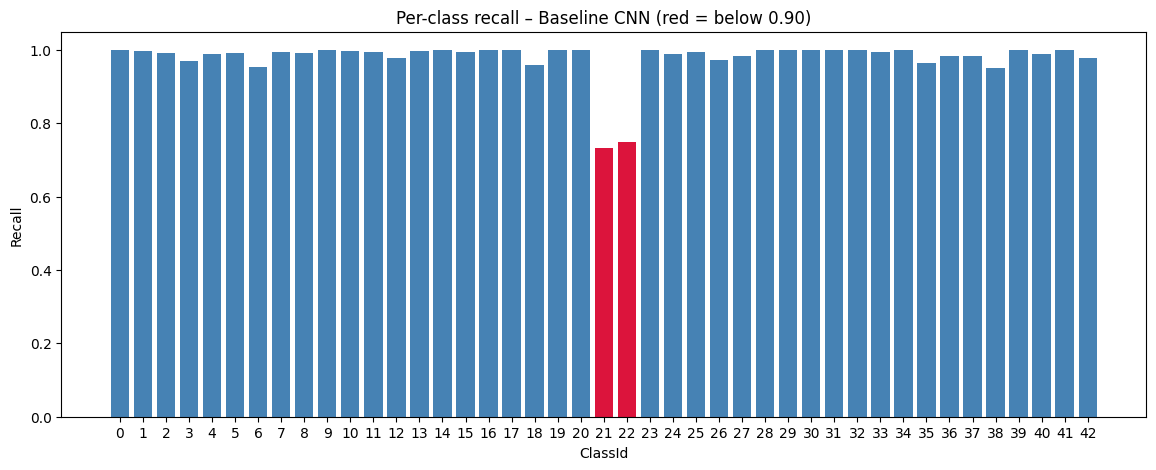

,class,recall,support
21,Double curve,0.733333,90
22,Bumpy road,0.750000,120
38,Keep right,0.950725,690
6,End of speed limit (80km/h),0.953333,150
18,General caution,0.958974,390
35,Ahead only,0.964103,390
3,Speed limit (60km/h),0.971111,450
26,Traffic signals,0.972222,180
42,End of no passing by vehicles over 3.5t,0.977778,90
12,Priority road,0.978261,690


In [17]:
# Per-class recall
recall = recall_score(y_test, pred, average=None, labels=np.arange(NUM_CLASSES))
rdf = pd.DataFrame({"class": CLASS_NAMES, "recall": recall, "support": np.bincount(y_test, minlength=NUM_CLASSES)})
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(range(NUM_CLASSES), recall, color=np.where(recall < 0.9, "crimson", "steelblue"))
ax.set_xticks(range(NUM_CLASSES)); ax.set_ylim(0, 1.05); ax.set_xlabel("ClassId"); ax.set_ylabel("Recall")
ax.set_title(f"Per-class recall – {best_name} (red = below 0.90)"); plt.show()
rdf.sort_values("recall").head(10)

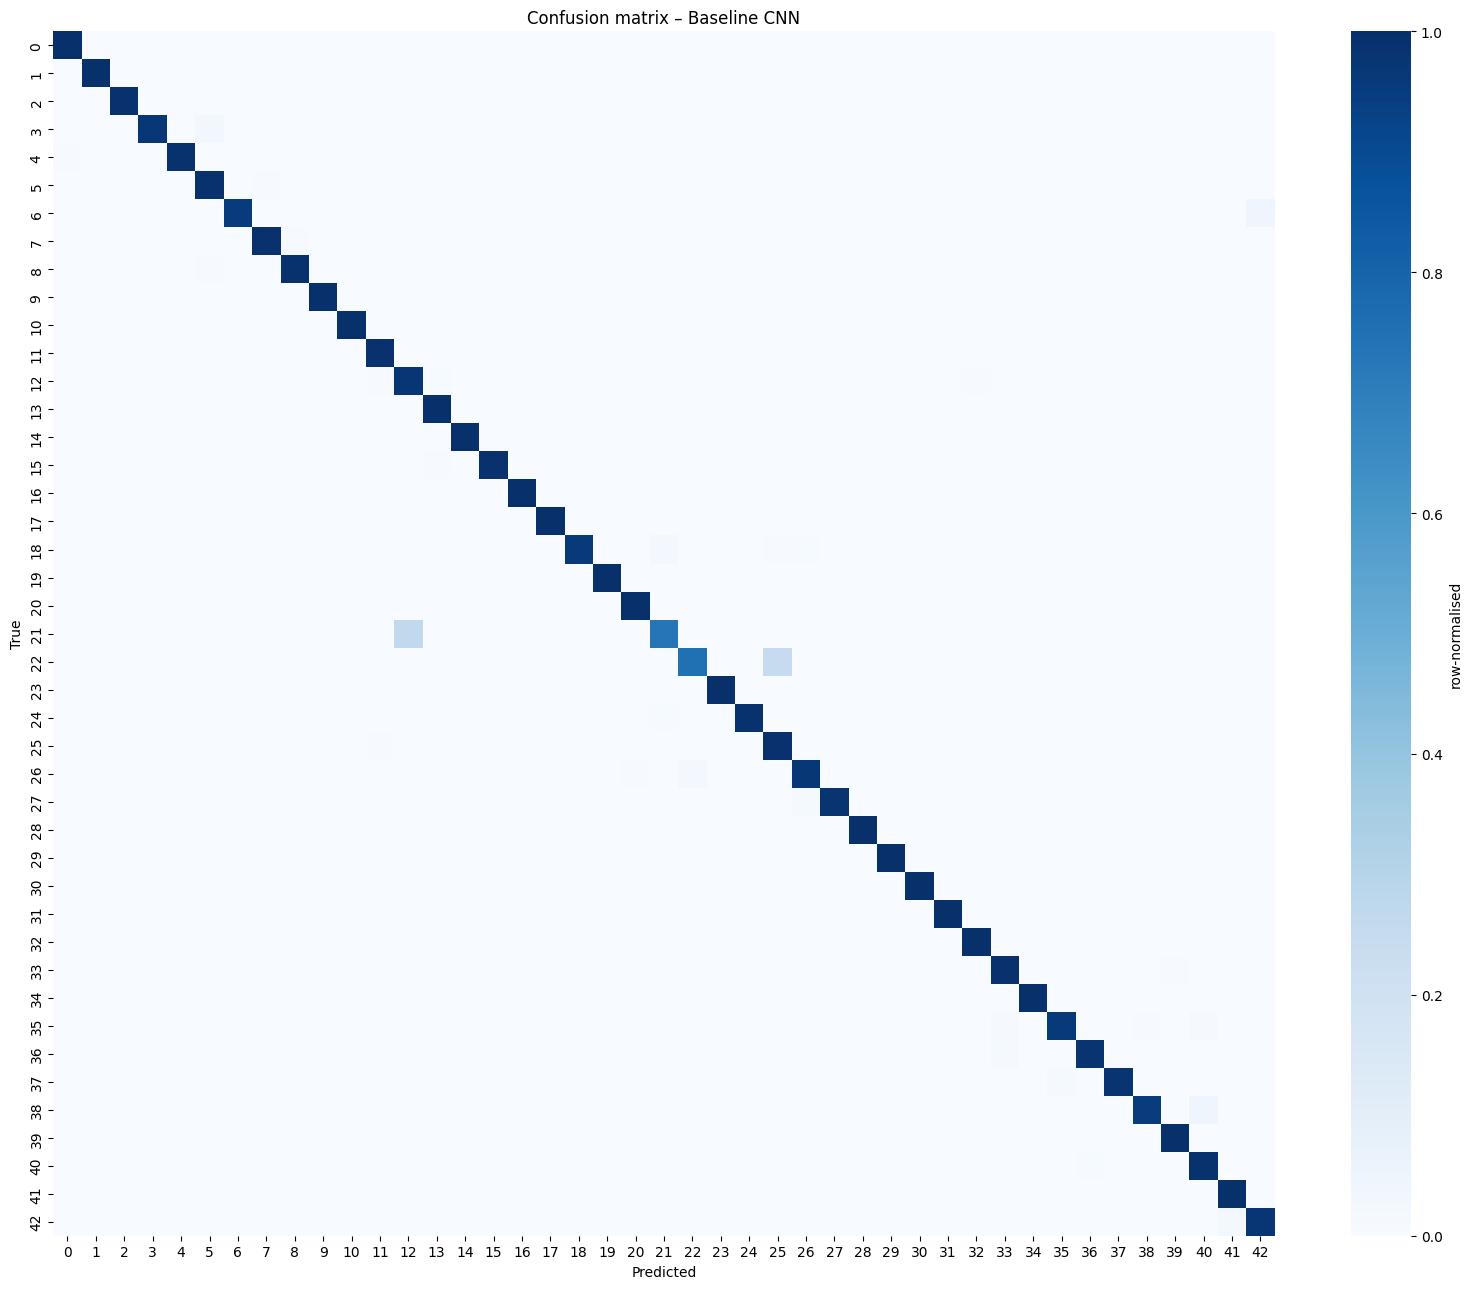

,count,true,predicted as
0,32,Keep right,Roundabout mandatory
1,30,Bumpy road,Road work
2,24,Double curve,Priority road
3,13,Speed limit (60km/h),Speed limit (80km/h)
4,9,General caution,Double curve
5,7,Priority road,Yield
6,7,End of speed limit (80km/h),End of no passing by vehicles over 3.5t
7,6,Ahead only,Turn right ahead
8,5,Ahead only,Roundabout mandatory
9,5,Priority road,Right-of-way at next intersection


In [18]:
cm = confusion_matrix(y_test, pred, labels=np.arange(NUM_CLASSES))
cmn = cm / cm.sum(1, keepdims=True)
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(cmn, cmap="Blues", ax=ax, xticklabels=range(NUM_CLASSES), yticklabels=range(NUM_CLASSES), cbar_kws={"label": "row-normalised"})
ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_title(f"Confusion matrix – {best_name}")
plt.tight_layout(); plt.savefig(ARTIFACTS / "confusion_matrix.png", dpi=120); plt.show()

# Most confused pairs
off = cm.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j], i, j) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if off[i, j] > 0], reverse=True)[:10]
pd.DataFrame([(n, CLASS_NAMES[i], CLASS_NAMES[j]) for n, i, j in pairs], columns=["count", "true", "predicted as"])

## 13. Error Analysis & Robustness

199 errors out of 12630 (1.58%); mean confidence on errors 0.78 vs correct 0.99


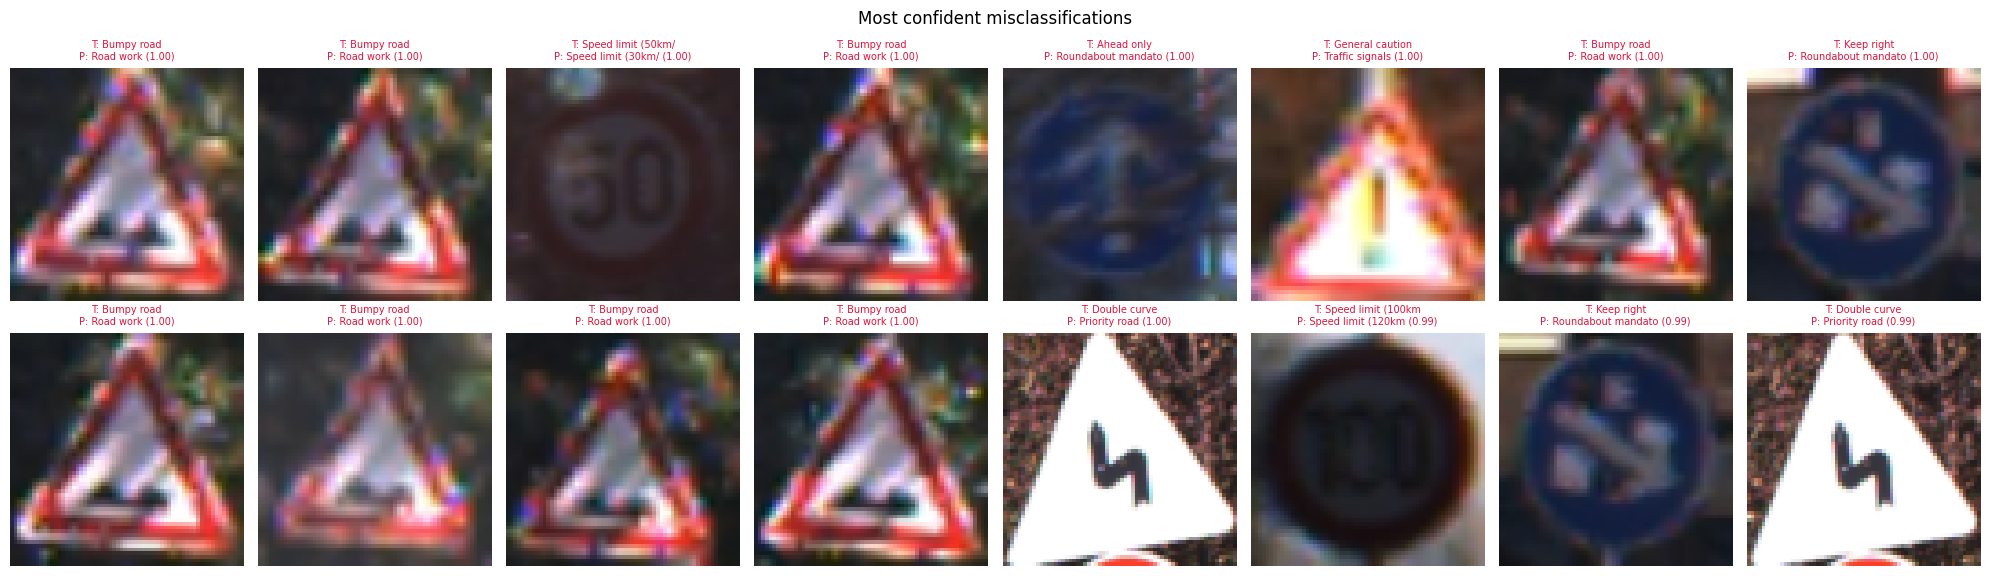

            mean  count
size_bin               
<30       0.9748   1626
30-45     0.9878   5470
45-60     0.9895   2773
>60       0.9775   2761
              mean  count
bright_bin               
darkest     0.9921   3158
dark        0.9832   3157
bright      0.9823   3157
brightest   0.9794   3158


In [19]:
wrong = np.where(pred != y_test)[0]
conf = probs.max(1)
print(f"{len(wrong)} errors out of {len(y_test)} ({len(wrong)/len(y_test):.2%}); mean confidence on errors {conf[wrong].mean():.2f} vs correct {conf[pred==y_test].mean():.2f}")
show = wrong[np.argsort(-conf[wrong])][:16]     # most confident mistakes
fig, axes = plt.subplots(2, 8, figsize=(20, 6))
for a, i in zip(axes.ravel(), show):
    a.imshow(X_test[i]); a.axis("off")
    a.set_title(f"T: {CLASS_NAMES[y_test[i]][:18]}\nP: {CLASS_NAMES[pred[i]][:18]} ({conf[i]:.2f})", fontsize=7, color="crimson")
plt.suptitle("Most confident misclassifications"); plt.tight_layout(); plt.show()

# Do errors correlate with small / dark images?
tdf = test_df.assign(correct=(pred == y_test), brightness=X_test.reshape(len(X_test), -1).mean(1))
tdf["size_bin"] = pd.cut(tdf.Width, [0, 30, 45, 60, 1000], labels=["<30", "30-45", "45-60", ">60"])
tdf["bright_bin"] = pd.qcut(tdf.brightness, 4, labels=["darkest", "dark", "bright", "brightest"])
print(tdf.groupby("size_bin").correct.agg(["mean", "count"]).round(4))
print(tdf.groupby("bright_bin").correct.agg(["mean", "count"]).round(4))

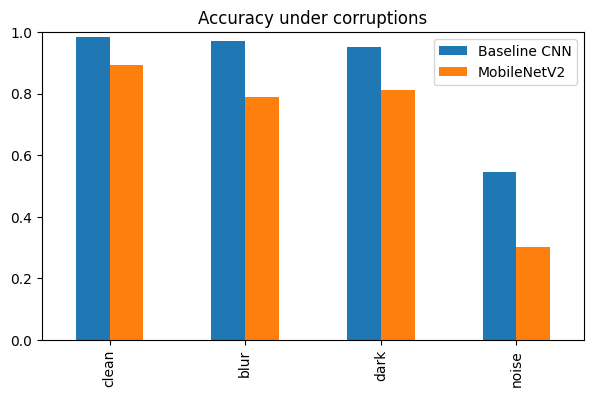

,Baseline CNN,MobileNetV2
clean,0.9833,0.8917
blur,0.9700,0.7887
dark,0.9523,0.8107
noise,0.5453,0.3030


In [20]:
# Robustness: how does accuracy degrade with blur / darkness / noise? (proxy for 'controlled data vs real road')
from PIL import ImageFilter
def corrupt(X, kind):
    out = np.empty_like(X)
    for i, im in enumerate(X):
        if kind == "blur":    out[i] = np.asarray(Image.fromarray(im).filter(ImageFilter.GaussianBlur(2)))
        elif kind == "dark":  out[i] = (im * 0.35).astype(np.uint8)
        elif kind == "noise": out[i] = np.clip(im + np.random.normal(0, 25, im.shape), 0, 255).astype(np.uint8)
        else:                 out[i] = im
    return out
rob = {}
idx = np.random.RandomState(0).choice(len(X_test), 3000, replace=False)
for kind in ["clean", "blur", "dark", "noise"]:
    Xc = corrupt(X_test[idx], kind)
    rob[kind] = {n: accuracy_score(y_test[idx], m.predict(Xc.astype("float32"), batch_size=256, verbose=0).argmax(1))
                 for n, m in [("Baseline CNN", baseline), ("MobileNetV2", transfer)]}
rob_df = pd.DataFrame(rob).T.round(4); rob_df.plot.bar(figsize=(7, 4), ylim=(0, 1), title="Accuracy under corruptions"); plt.show(); rob_df

## 14. Export the Model Artifact, Streamlit App & README
The saved `.keras` model contains its own resizing/rescaling layers, so the app only has to resize an upload to 64×64 RGB – no other preprocessing. The app loads the artifact **without retraining**.

In [21]:
MODEL_PATH = ARTIFACTS / "traffic_sign_model.keras"
best_model.save(MODEL_PATH)
json.dump({"class_names": CLASS_NAMES, "img_size": IMG_SIZE, "model": best_name}, open(ARTIFACTS / "meta.json", "w"), indent=2)
print("Saved", MODEL_PATH, f"{MODEL_PATH.stat().st_size/1e6:.1f} MB")

# Optional model compression: TFLite with dynamic-range quantisation
try:
    conv = tf.lite.TFLiteConverter.from_keras_model(best_model)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]; tflite = conv.convert()
except Exception as e:                                     # Keras 3: go via an exported SavedModel instead
    print("from_keras_model failed (", type(e).__name__, ") - converting via SavedModel")
    best_model.export(str(ARTIFACTS / "saved_model"))
    conv = tf.lite.TFLiteConverter.from_saved_model(str(ARTIFACTS / "saved_model"))
    conv.optimizations = [tf.lite.Optimize.DEFAULT]; tflite = conv.convert()
(ARTIFACTS / "traffic_sign_model.tflite").write_bytes(tflite)
interp = tf.lite.Interpreter(model_content=tflite); interp.allocate_tensors()
inp, outp = interp.get_input_details()[0], interp.get_output_details()[0]
def tflite_predict(X):
    res = []
    for im in X:
        interp.set_tensor(inp["index"], im[None].astype("float32")); interp.invoke(); res.append(interp.get_tensor(outp["index"])[0])
    return np.array(res)
sub = slice(0, 1000)
print(f"TFLite size {len(tflite)/1e6:.2f} MB | acc on 1000 test imgs: {accuracy_score(y_test[sub], tflite_predict(X_test[sub]).argmax(1)):.4f}"
      f" vs Keras {accuracy_score(y_test[sub], pred[sub]):.4f}")

Saved artifacts/traffic_sign_model.keras 4.1 MB


INFO:tensorflow:Assets written to: /var/folders/2r/8r4r0j050xlc9fqy9_r0xz340000gn/T/tmpn2qf77xa/assets


INFO:tensorflow:Assets written to: /var/folders/2r/8r4r0j050xlc9fqy9_r0xz340000gn/T/tmpn2qf77xa/assets


Saved artifact at '/var/folders/2r/8r4r0j050xlc9fqy9_r0xz340000gn/T/tmpn2qf77xa'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name='keras_tensor_6')
Output Type:
  TensorSpec(shape=(None, 43), dtype=tf.float32, name=None)
Captures:
  5719867808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5719867632: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5719869216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5719869920: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5719867984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5719868864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5719871328: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5719901104: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5719913568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5719914624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  5719903744: TensorS

W0000 00:00:1792253258.125812 13059181 tf_tfl_flatbuffer_helpers.cc:365] Ignored output_format.
W0000 00:00:1792253258.125982 13059181 tf_tfl_flatbuffer_helpers.cc:368] Ignored drop_control_dependency.


2026-10-17 21:37:38.127708: I tensorflow/cc/saved_model/reader.cc:83] Reading SavedModel from: /var/folders/2r/8r4r0j050xlc9fqy9_r0xz340000gn/T/tmpn2qf77xa
2026-10-17 21:37:38.128848: I tensorflow/cc/saved_model/reader.cc:52] Reading meta graph with tags { serve }
2026-10-17 21:37:38.128857: I tensorflow/cc/saved_model/reader.cc:147] Reading SavedModel debug info (if present) from: /var/folders/2r/8r4r0j050xlc9fqy9_r0xz340000gn/T/tmpn2qf77xa
I0000 00:00:1792253258.138445 13059181 mlir_graph_optimization_pass.cc:425] MLIR V1 optimization pass is not enabled
2026-10-17 21:37:38.140047: I tensorflow/cc/saved_model/loader.cc:236] Restoring SavedModel bundle.
2026-10-17 21:37:38.195032: I tensorflow/cc/saved_model/loader.cc:220] Running initialization op on SavedModel bundle at path: /var/folders/2r/8r4r0j050xlc9fqy9_r0xz340000gn/T/tmpn2qf77xa
2026-10-17 21:37:38.209908: I tensorflow/cc/saved_model/loader.cc:471] SavedModel load for tags { serve }; Status: success: OK. Took 82220 microsecon

TFLite size 0.36 MB | acc on 1000 test imgs: 0.9890 vs Keras 0.9890


In [22]:
APP = r"""
import json, numpy as np, streamlit as st
from PIL import Image
import tensorflow as tf

ART = "artifacts"
@st.cache_resource
def load():
    meta = json.load(open(f"{ART}/meta.json"))
    return tf.keras.models.load_model(f"{ART}/traffic_sign_model.keras"), meta

model, meta = load()
S = meta["img_size"]; names = meta["class_names"]

st.title("🚦 Traffic Sign Recognition (GTSRB)")
st.caption("Learning prototype – NOT a safety-certified driving component. Upload a tightly cropped image of a single sign.")
f = st.file_uploader("Upload a traffic sign image", type=["png", "jpg", "jpeg", "ppm"])
if f:
    img = Image.open(f).convert("RGB")
    st.image(img, caption="Input", width=250)
    x = np.asarray(img.resize((S, S), Image.BILINEAR), dtype="float32")[None]
    p = model.predict(x, verbose=0)[0]
    top = p.argsort()[::-1][:5]
    st.subheader(f"Prediction: {names[top[0]]}  ({p[top[0]]:.1%})")
    if p[top[0]] < 0.6:
        st.warning("Low confidence – the image may be blurry, dark, badly cropped or not a GTSRB-style sign.")
    st.bar_chart({names[i]: float(p[i]) for i in top})
"""
open("app.py", "w").write(APP.strip())
open("requirements.txt", "w").write("# Tested with tensorflow 2.19.1. tensorflow 2.20 aborts on import on macOS when pyarrow (a streamlit dependency) is installed (tensorflow/tensorflow#98563); the saved .keras model needs Keras 3 (tensorflow>=2.16).\ntensorflow>=2.16,<2.20\nstreamlit\npillow\nnumpy\npandas\nscikit-learn\nmatplotlib\nseaborn\n")

README = """# Traffic Sign Recognition (GTSRB) – CNN + Transfer Learning

Classifies a cropped traffic-sign image into one of 43 GTSRB classes. Learning prototype only – not for real driving use.

## Setup
```
python -m venv .venv && source .venv/bin/activate
pip install -r requirements.txt
```
TensorFlow is pinned to 2.16–2.19: 2.20 crashes on import on macOS when pyarrow (a Streamlit dependency) is installed, and the saved `.keras` model needs Keras 3. Tested with TensorFlow 2.19.1 on Python 3.9.
## Reproduce training
Open `Traffic_Sign_Recognition.ipynb` and run all cells. It downloads GTSRB from the official source, trains a baseline CNN and a
MobileNetV2 transfer model, evaluates on the official test set and writes `artifacts/` (model, meta.json, metrics, plots).
## Run the demo (no retraining needed)
```
streamlit run app.py
```
Upload a PNG/JPG of a single, tightly cropped sign. The app shows the top-5 classes with confidence.
## Layout
- `Traffic_Sign_Recognition.ipynb` – data access, EDA, models, evaluation
- `artifacts/` – `traffic_sign_model.keras`, `.tflite`, `meta.json`, `experiments.csv`, `test_summary.csv`
- `app.py` – Streamlit interface
## Limitations
Trained on German signs in cropped, controlled crops; will not detect signs in full scenes and may fail on blur, darkness, occlusion or non-German designs.
"""
open("README.md", "w").write(README)
print("Wrote app.py, requirements.txt, README.md")

Wrote app.py, requirements.txt, README.md


## 15. Demo: Three Sample Predictions + One Known Failure
Sample images are saved to `demo_samples/` so they can also be uploaded to the Streamlit app.

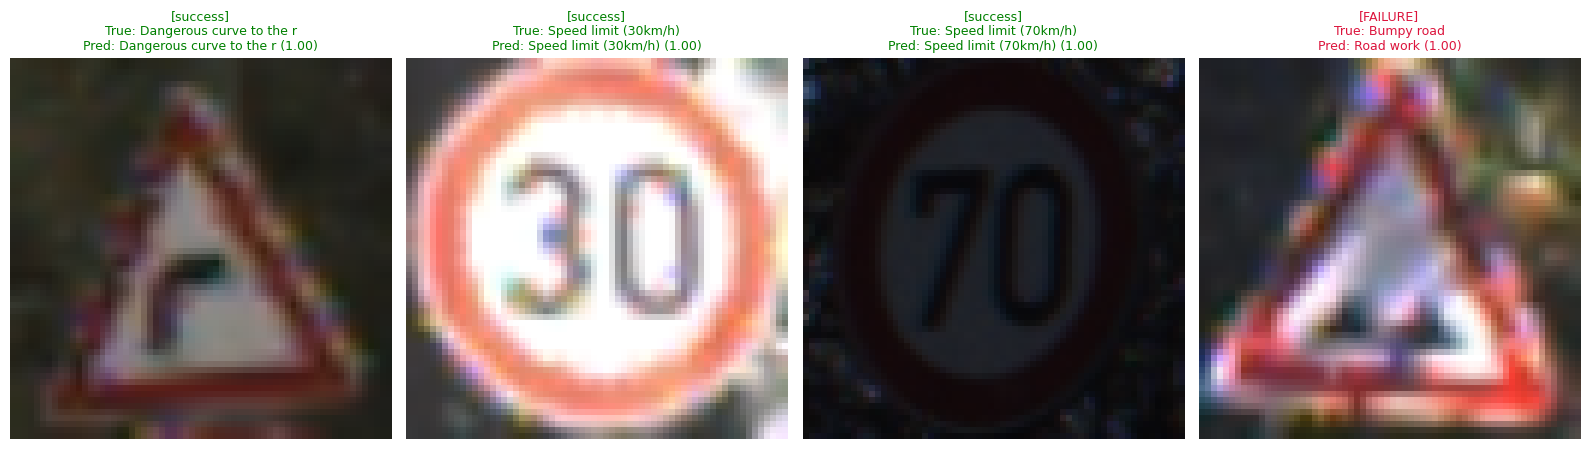

In [23]:
Path("demo_samples").mkdir(exist_ok=True)
loaded = keras.models.load_model(MODEL_PATH)       # prove the artifact loads without retraining
good = [i for i in np.where(pred == y_test)[0] if conf[i] > 0.95]
picks = [("success", i) for i in np.random.RandomState(1).choice(good, 3, replace=False)] + [("FAILURE", wrong[np.argsort(-conf[wrong])][0])]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for a, (tag, i) in zip(axes, picks):
    Image.fromarray(X_test[i]).resize((128, 128)).save(f"demo_samples/{tag}_{i}.png")
    p = loaded.predict(X_test[i:i+1].astype("float32"), verbose=0)[0]
    a.imshow(X_test[i]); a.axis("off")
    a.set_title(f"[{tag}]\nTrue: {CLASS_NAMES[y_test[i]][:24]}\nPred: {CLASS_NAMES[p.argmax()][:24]} ({p.max():.2f})", fontsize=9,
                color="green" if tag == "success" else "crimson")
plt.tight_layout(); plt.show()

## 16. Conclusions, Limitations & Responsible Use
**Results summary (official test set, 12,630 images)**

| Model | Accuracy | Macro F1 | Top-5 | Latency (ms/img, CPU) | Params |
|---|---|---|---|---|---|
| **Custom CNN (selected)** | **98.42%** | **0.976** | 99.93% | 9.0 | 333K |
| MobileNetV2 (fine-tuned) | 88.96% | 0.854 | 99.01% | 28.6 | 2.31M |

- The custom CNN was selected on **validation** macro-F1 (0.986 vs 0.893) and confirmed on test: macro precision / recall 0.976 / 0.978, and 38 of 43 classes have recall ≥ 0.96.
- 199 test errors (1.58%). Weakest classes: **Double curve** (recall 0.73) and **Bumpy road** (0.75). Most frequent confusions: Keep right → Roundabout mandatory (32), Bumpy road → Road work (30), Double curve → Priority road (24), Speed limit 60 → 80 km/h (13).
- Errors average 0.78 confidence vs 0.99 for correct predictions, but some errors are made at ~100% confidence (e.g. the demo failure: Bumpy road → Road work).
- The quantised TFLite model is 0.36 MB and matched the Keras model on a 1,000-image check (0.989).

**The advanced model did not beat the baseline.** The goal in §1 was for transfer learning to clearly beat the baseline; it did not. With the backbone frozen, MobileNetV2 plateaued at ≈68% validation accuracy – ImageNet features computed on tiny 64 px sign crops separate the classes poorly. Fine-tuning only the top 40 layers reached ≈91% before the learning rate decayed and early stopping ended training. Next step: fine-tune the whole backbone at lr ≈ 1e-4 – 3e-4 for more epochs (optionally at 128×128 input) and compare EfficientNet-B0.

**Is it usable for the stated context?** Yes for learning and ADAS *prototyping* on cropped, GTSRB-style sign images: high and balanced accuracy, 9 ms per image on a laptop CPU, and a 0.36 MB compressed model. **Not** for in-vehicle decisions: it needs a pre-cropped sign, is fragile to sensor noise and can be confidently wrong.

**Limitations & risks**
- *Sensor noise* – accuracy falls from 98.3% to **54.5%** with Gaussian noise (σ = 25), while blur (97.0%) and darkening (95.2%) are handled much better. Noise was not part of the augmentation pipeline; this is the biggest robustness gap.
- *Small signs* – originals under 30 px reach 97.5% accuracy vs 99.0% for 45–60 px signs.
- *Class imbalance* – the two weakest classes have only 90 and 120 test images; class weights and augmentation were applied, and targeted augmentation / oversampling could help further.
- *Visually similar signs* – most confusions are between signs that share shape and colour and differ only in a small pictogram or arrow layout. The Double curve → Priority road confusion (different shapes) should be checked for image-quality or labelling issues.
- *Controlled data ≠ real roads* – GTSRB contains pre-cropped German signs only: no detection stage and limited weather / occlusion diversity. Out-of-distribution inputs still receive a confident-looking prediction.
- *Limited sweep evidence* – 8-epoch, single-seed runs cannot show the benefit of augmentation or class weights.
- **Responsible use:** educational prototype; **not** a safety-certified autonomous-driving component. A real deployment would need sign detection, temporal smoothing, calibration, extensive field testing and fail-safe design.

**Future scope:** full-backbone transfer learning (MobileNetV2 / EfficientNet); noise, JPEG, motion-blur and weather augmentation; full-length multi-seed ablations; confidence calibration and out-of-distribution rejection; a detector (e.g. YOLO on GTSDB) for full street scenes; FastAPI / Docker packaging and edge-device benchmarks.